PROGETTO : RICONOSCIMENTO GESTI DELLA MANO

In [1]:
import tensorflow as tf

from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, Flatten, Dense

In [2]:
train_datagen = ImageDataGenerator(
    rescale=1./255, 
    rotation_range=40,
    width_shift_range=0.2,
    shear_range=0.2,
    horizontal_flip=True,
    fill_mode='nearest'
    )

In [3]:
train_generator = train_datagen.flow_from_directory(
    'rps',
    target_size=(150, 150),
    batch_size=32,
    class_mode='categorical')

Found 2520 images belonging to 3 classes.


In [4]:
test_datagen = ImageDataGenerator(rescale=1./255)

test_generator = test_datagen.flow_from_directory(
    'rps-test-set',
    target_size=(150, 150),
    batch_size=32,
    class_mode='categorical',
    shuffle=False
)

Found 372 images belonging to 3 classes.


In [5]:
model = Sequential([
    Input(shape=(150, 150, 3)),

    Conv2D(32, (3,3),
           activation='relu'),
           MaxPooling2D((2,2)),
           
           Conv2D(64, (3,3),
                  activation='relu'),
                  MaxPooling2D((2,2)),

                  Conv2D(128, (3,3),
                         activation='relu'),
                         MaxPooling2D((2,2)),

                         Flatten(),
                         Dense(512, activation='relu'),
                         Dense(3, activation='softmax')
])

In [6]:
model.compile(

    optimizer='adam',

    loss='categorical_crossentropy',

    metrics=['accuracy']
)

In [7]:
class StopAt98(tf.keras.callbacks.Callback):

    def on_epoch_end(self, epoch, logs=None):

        if logs.get('accuracy') is not None and logs.get('accuracy') > 0.98:

            print("\nAccuracy superiore al 98%. Training interrotto.")
            
            self.model.stop_training = True

callback = StopAt98()

In [8]:
history = model.fit(

    train_generator,
    epochs=20,
    callbacks=[callback]
)

Epoch 1/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 46s 567ms/step - accuracy: 0.4972 - loss: 1.1551
Epoch 2/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 17s 219ms/step - accuracy: 0.8163 - loss: 0.4400
Epoch 3/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 17s 219ms/step - accuracy: 0.9218 - loss: 0.2319
Epoch 4/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 17s 215ms/step - accuracy: 0.9429 - loss: 0.1660
Epoch 5/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 18s 231ms/step - accuracy: 0.9615 - loss: 0.1210
Epoch 6/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 17s 215ms/step - accuracy: 0.9683 - loss: 0.0949
Epoch 7/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 17s 218ms/step - accuracy: 0.9750 - loss: 0.0865
Epoch 8/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 17s 219ms/step - accuracy: 0.9758 - loss: 0.0781
Epoch 9/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 17s 220ms/step - accuracy: 0.9790 - loss: 0.0714
Epoch 10/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 218ms/step - accuracy: 0.9845 - loss: 0.0555
Accuracy superiore al 98%. Training interrotto.
79/79 ━━━━━━━━━━━━━━━━━━━━ 17s 218ms/step - accuracy: 0.9845 - loss: 0.0555


In [11]:
test_loss, test_accuracy = model.evaluate(test_generator)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 58ms/step - accuracy: 0.9301 - loss: 0.1089
Test Loss: 0.1089128851890564
Test Accuracy: 0.9301075339317322


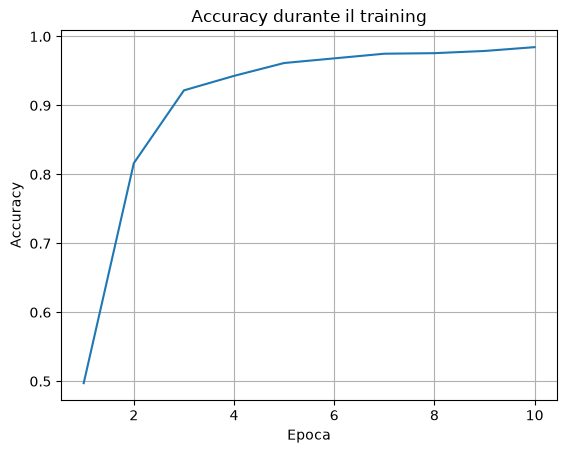

In [12]:
import matplotlib.pyplot as plt

epoca = range(1, len(history.history['accuracy']) +1)

plt.plot(epoca, history.history['accuracy'])
plt.title('Accuracy durante il training')
plt.xlabel('Epoca')
plt.ylabel('Accuracy')
plt.grid(True)
plt.show()

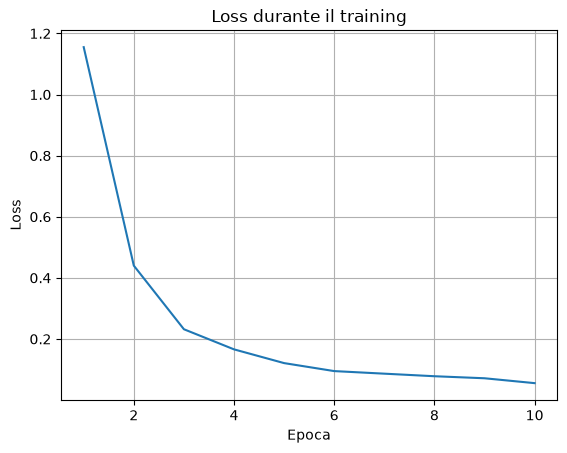

In [13]:
epoca = range(1, len(history.history['loss']) +1)

plt.plot(epoca, history.history['loss'])
plt.title('Loss durante il training')
plt.xlabel('Epoca')
plt.ylabel('Loss')
plt.grid(True)
plt.show()

In [23]:
import numpy as np
from tensorflow.keras.utils import load_img, img_to_array

percorso_immagine = "Mani/mano_test.jpg"

img = load_img(
    percorso_immagine,
    target_size=(150, 150)
)

img_array = img_to_array(img)
img_array = img_array / 255.0
img_array = np.expand_dims(img_array, axis=0)

predizione = model.predict(img_array)

classi = ['Carta', 'Sasso', 'Forbice']

indice = np.argmax(predizione)
risultato = classi[indice]

print("Predizione:", risultato)
print("Confidenza", round(predizione[0][indice] * 100,2), "%")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
Predizione: Sasso
Confidenza 78.54 %


In [19]:
percorso_immagine1 = "rps-test-set/paper/testpaper04-06.png"

img = load_img(
    percorso_immagine1,
    target_size=(150, 150)
)

img_array = img_to_array(img)
img_array = img_array / 255.0
img_array = np.expand_dims(img_array, axis=0)

predizione = model.predict(img_array)

classi = ['Carta', 'Sasso', 'Forbice']

indice = np.argmax(predizione)
risultato = classi[indice]

print("Predizione:", risultato)
print("Confidenza", round(predizione[0][indice] * 100,2), "%")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
Predizione: Carta
Confidenza 100.0 %


Analisi Domain Gap

Il modello ha ottenuto una buona accuratezza sul dataset di test,
pari a circa il 93%.
Anche le immagini campione CGI sono state classificate correttamente
nelle tre categorie:

CARTA
SASSO
FORBICE

Tuttavia con immagini reali della mano, il modello ha mostrato maggiori
difficoltà, classificando diversi gesti come sasso.

A causa del Domain Gap per varie caratteristiche (illuminazione, colore pelle, angolazione, sfondo) 
il modello risulta più efficace sulle
immagini del dataset rispetto a quelle reali.

MINI GIOCO

In [41]:
import random
import numpy as np
from tensorflow.keras.utils import load_img, img_to_array

foto_giocatore = [
    "Mani/mano_test.jpg",
    "Mani/mano_test2.jpg",
    "Mani/mano_test3.jpg"
]

percorso_immagine= random.choice(foto_giocatore)

img = load_img(percorso_immagine, target_size=(150, 150))
img_array = img_to_array(img)
img_array = img_array / 255.0
img_array = np.expand_dims(img_array, axis=0)

predizione = model.predict(img_array)

classi = ['Carta', 'Sasso', 'Forbice']
indice = np.argmax(predizione)

giocatore = classi[indice]
confidenza = predizione[0][indice] * 100

computer = random.choice(classi)

print("Tu:", giocatore)
print("Confidenza:", round(confidenza, 2), "%")
print("Computer:", computer)

if giocatore == computer:

    print("PAREGGIO")

elif (

    (giocatore == "Carta" and computer == "Sasso") or

    (giocatore == "Sasso" and computer == "Forbice") or

    (giocatore == "Forbice" and computer == "Carta")
):
    print("HAI VINTO")

else:
    print("HA VINTO IL COMPUTER")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step
Tu: Sasso
Confidenza: 85.99 %
Computer: Carta
HA VINTO IL COMPUTER


Come applicazione finale del modello è stato realizzato
un semplice minigioco.
Ad ogni esecuzione viene scelta casualmente una delle tre immagini reali della mia mano,
che viene analizzata dal CNN per riconoscere il gesto.
Stesso discorso per il computer, dopo di che viene stabilito il vincitore.

A causa del Domain Gap evidenziato precedentemente, il riconoscimento delle immagini
reali non avviene in modo esemplare, ragion per cui uscirà sempre sasso per il giocatore.
L'esito del minigioco dipenderà esclusivamente dalla scelta random del computer